# Is the PD BVOC SOA signal an artefact of prescribing the emissions?

**Question.** In `BVOC_PD` = LCC_PD − LCC_PD_fBVOCctrlPD (figure `results/figures/PD_fBVOCctrlPD_bvoc_context_maps_2001_2014.png`), the SOA burden falls by about −4 % **everywhere**, including the Southern Hemisphere and the Arctic Ocean. Yet the ISOP/MTERP emissions north of 45°N go **up**, and global emissions fall by only −1.3 %.

**Hint (2001–2014, existing runs).** LCC_PD_fBVOCctrlPD has the **same emissions** as CTRL_PD (±0.05 %), but about **+3 % more SOA** in every latitude band and season. The fBVOC run differs from CTRL_PD in two ways: (i) the emission method (MEGAN off, prescribed climatology) and (ii) the land (LCC land + LCC spin-up). These three runs cannot separate the two.

**Section 3** shows the evidence from the existing runs; **sections 4–6** the test run.

**Test run.** `CTRL_PD_fBVOCctrlPD` (script `cases-scripts/14c-…`) has CTRL land, the same restart and nudging as CTRL_PD `-20261023`, and CTRL_PD's own 19 MEGAN species prescribed. It covers 2000–2002; 2000 is dropped as spin-up.

| Key | Contrast | What it measures |
|---|---|---|
| **A** | CTRL_PD_fBVOCctrlPD − CTRL_PD | **emission-method artefact alone** (same land, same emissions on average) |
| **E** | LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD | land effect with emissions held fixed |
| **B** | LCC_PD_fBVOCctrlPD − CTRL_PD | A + E |
| **C** | LCC_PD − LCC_PD_fBVOCctrlPD | `BVOC_PD`, the contrast in the figure |
| **D** | LCC_PD − CTRL_PD | `Total_PD` (interactive emissions in both runs) |
| **C+A** | C corrected for the artefact | estimate of the BVOC effect without the method artefact |

**How to read it.** If **A ≈ +3 %** everywhere, the uniform SOA decrease in C is mostly the prescription artefact. If **A ≈ 0**, it comes from the land (E). Caveats: only 2 comparison years (2001–2002); the prescribed emissions are the 2001–2014 climatology, not the actual 2001–2002 emissions (see the emission check); old (pre-CO₂-fix) chain, like the figure.

Outputs: `fbvoc_prescription_artefact_outputs/` (`figures/`, `tables/`). Updated automatically by `run_when_done/run_when_done.sh` once the run is postprocessed.

In [1]:
import os, sys
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

REPO = Path('/cluster/home/adelez/BOREAL-FOREST-EXPANSION')
sys.path.insert(0, str(REPO / 'src'))
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.analysis.stats import cellwise_pvalue, fdr_mask

PROC = fm.POSTPROCESSED_DIR / '2001-2014-all-bvoc-pre-co2-fix'   # old chain (moved 2026-11-02)
OUT = Path('fbvoc_prescription_artefact_outputs')
for sub in ('figures', 'tables'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

RUNS = {'ctrl': 'CTRL_PD', 'lcc': 'LCC_PD', 'fbvoc': 'LCC_PD_fBVOCctrlPD', 'art': 'CTRL_PD_fBVOCctrlPD_test2yr'}   # old-chain 2-yr test, renamed 2026-11-02
# Testing only: ARTEFACT_STANDIN=<alias> replaces the artefact run, to check the code before the run exists
STANDIN = os.environ.get('ARTEFACT_STANDIN')
if STANDIN:
    RUNS['art'] = STANDIN
    print(f'!!! STAND-IN: art = {STANDIN}. These numbers are NOT the artefact run !!!')

def span(alias, cls='SOA'):
    # (first, last) year of the processed file alias/cls; None if there is none
    f = sorted(PROC.glob(f'{alias}_atm_{cls}_*-*.nc'))
    if not f:
        return None
    y0, y1 = f[0].stem.rsplit('_', 1)[1].split('-')
    return int(y0), int(y1)

HAVE_ART = span(RUNS['art']) is not None
ART_SPAN = (2001, 2002) if (STANDIN or not HAVE_ART) else span(RUNS['art'])
YEARS2 = list(range(ART_SPAN[0], ART_SPAN[1] + 1))   # years of the artefact run
YEARS14 = list(range(2001, 2015))
for k, a in RUNS.items():
    print(f'{k:6s} {a:22s} processed years: {span(a)}')
print('artefact run available:', HAVE_ART, '| comparison years:', YEARS2)

ctrl   CTRL_PD                processed years: (2001, 2014)
lcc    LCC_PD                 processed years: (2001, 2014)
fbvoc  LCC_PD_fBVOCctrlPD     processed years: (2001, 2014)
art    CTRL_PD_fBVOCctrlPD_test2yr processed years: (2001, 2002)
artefact run available: True | comparison years: [2001, 2002]


## 1. Yearly fields
Calendar-year means weighted by month length (`fm.annual_mean`). 3-D fields: lowest model level. `SOA_cb` = offline column burden of interstitial SOA (A1 + NA), the field in the figure. `cb_SOA_LV/SV` = model column burdens of the SOA gas-phase precursors. The two periods are kept apart: **2yr** = the artefact-run years, **14yr** = 2001–2014.

In [2]:
def open_years(alias, cls, years):
    y0, y1 = span(alias, cls)
    ds = xr.open_dataset(PROC / fm.filename(alias, cls, y0, y1).name)
    ds = ds.isel(time=ds['time'].dt.year.isin(years).values)
    missing = sorted(set(years) - set(np.unique(ds['time'].dt.year.values)))
    if missing:
        raise ValueError(f'{alias} {cls}: years {missing} missing')
    return ds

def ym(v, lev=None, scale=1.0):
    def f(ds):
        da = ds[v] if lev is None else ds[v].isel(lev=lev)
        return fm.annual_mean(da, ds) * scale
    return f

# name: (class, yearly field, units, report relative change [%]?)
VARS = {
    'SFISOP':     ('BVOC', ym('SFISOP'), 'kg m-2 s-1', True),
    'SFMTERP':    ('BVOC', ym('SFMTERP'), 'kg m-2 s-1', True),
    'SFBCARY':    ('BVOC', ym('SFBCARY'), 'kg m-2 s-1', True),
    'cb_ISOP':    ('BVOC', ym('cb_ISOP'), 'kg m-2', True),
    'cb_MTERP':   ('BVOC', ym('cb_MTERP'), 'kg m-2', True),
    'cb_SOA_LV':  ('SOA', ym('cb_SOA_LV'), 'kg m-2', True),
    'cb_SOA_SV':  ('SOA', ym('cb_SOA_SV'), 'kg m-2', True),
    'SOA_cb':     ('SOA', ym('SOA_cb', scale=1e6), 'mg m-2', True),
    'N_AER_sfc':  ('SOA', ym('N_AER', lev=-1), 'cm-3', True),
    'OH_sfc':     ('CHEM', ym('OH', lev=-1), 'mol mol-1', True),
    'O3_sfc':     ('CHEM', ym('O3', lev=-1), 'mol mol-1', True),
    'NO_sfc':     ('CHEM', ym('NO', lev=-1), 'mol mol-1', True),
    'CDNC_incld': ('CLOUDPROP', lambda ds: fm.yearly_field(ds, 'ACTNL_incld'), 'cm-3', True),
    'LWP':        ('CLOUDPROP', lambda ds: fm.yearly_field(ds, 'TGCLDLWP_gm2'), 'g m-2', True),
    'NET_toa':    ('RADIATIVE', ym('NET_toa'), 'W m-2', False),
}

def fields(alias, years):
    out, opened = {}, {}
    for name, (cls, fn, units, rel) in VARS.items():
        try:
            if cls not in opened:
                opened[cls] = open_years(alias, cls, years)
            out[name] = fn(opened[cls]).load()
        except (KeyError, TypeError, ValueError, FileNotFoundError) as e:
            print(f'  {alias}: {name} skipped ({type(e).__name__}: {e})')
    return out

F2 = {k: fields(a, YEARS2) for k, a in RUNS.items() if k != 'art' or HAVE_ART or STANDIN}
F14 = {k: fields(RUNS[k], YEARS14) for k in ('ctrl', 'lcc', 'fbvoc')}
print({k: len(v) for k, v in F2.items()}, {k: len(v) for k, v in F14.items()})

{'ctrl': 15, 'lcc': 15, 'fbvoc': 15, 'art': 15} {'ctrl': 15, 'lcc': 15, 'fbvoc': 15}


## 2. Changes by latitude band
Area-weighted (cos lat) band means of each year, then the change case1 − case2 in % of case2 (NET_toa: absolute, W m⁻²); the tables show the mean over years. **C+A** = C + A (sum of the % changes, a first-order approximation); **C+Ā** = the 14-yr C plus the mean of A.

In [3]:
BANDS = {'Global': (-90, 90), '90–30°S': (-90, -30), '30°S–30°N': (-30, 30), '30–45°N': (30, 45),
         '45–60°N': (45, 60), '60–90°N': (60, 90), '45–90°N': (45, 90)}
BAR_BANDS = ['Global', '90–30°S', '30°S–30°N', '45–60°N', '60–90°N']
CONTRASTS = {'A': ('art', 'ctrl'), 'E': ('fbvoc', 'art'), 'B': ('fbvoc', 'ctrl'),
             'C': ('lcc', 'fbvoc'), 'D': ('lcc', 'ctrl')}
LABELS = {k: f'{k}: {RUNS[a]} − {RUNS[b]}' for k, (a, b) in CONTRASTS.items()}
LABELS.update({'C+A': 'C+A: BVOC_PD corrected', 'C+Ā': 'C+Ā: BVOC_PD 2001–2014 corrected'})

def change(F, c1, c2, var, lo, hi):
    # yearly band-mean change case1 − case2: % of case2 (relative variables) or absolute
    a = fm.area_weighted_mean(F[c1][var], lat_min=lo, lat_max=hi)
    b = fm.area_weighted_mean(F[c2][var], lat_min=lo, lat_max=hi)
    return (100 * (a - b) / b if VARS[var][3] else a - b).values

CH = {}   # (period, contrast, variable, band) -> yearly values
for var in VARS:
    for band, (lo, hi) in BANDS.items():
        for key, (c1, c2) in CONTRASTS.items():
            if c1 in F2 and c2 in F2 and var in F2[c1] and var in F2[c2]:
                CH[('2yr', key, var, band)] = change(F2, c1, c2, var, lo, hi)
            if c1 in F14 and c2 in F14 and var in F14[c1] and var in F14[c2]:
                CH[('14yr', key, var, band)] = change(F14, c1, c2, var, lo, hi)
        if ('2yr', 'A', var, band) in CH:
            CH[('2yr', 'C+A', var, band)] = CH[('2yr', 'C', var, band)] + CH[('2yr', 'A', var, band)]
            CH[('14yr', 'C+Ā', var, band)] = CH[('14yr', 'C', var, band)] + CH[('2yr', 'A', var, band)].mean()

tab = pd.DataFrame([dict(variable=v, period=p, contrast=k, band=b, mean=x.mean(), n_years=len(x))
                    for (p, k, v, b), x in CH.items()])
T = tab.pivot_table(index=['variable', 'period', 'contrast'], columns='band', values='mean', sort=False)[list(BANDS)]
T.round(3).to_csv(OUT / 'tables' / 'changes_by_band.csv')
tab.to_csv(OUT / 'tables' / 'changes_by_band_long.csv', index=False)
pd.set_option('display.width', 200); pd.set_option('display.max_rows', 300)
print('Contrasts:'); [print('  ', LABELS[k]) for k in LABELS]
print(f'Saved {OUT}/tables/changes_by_band.csv')

Contrasts:
   A: CTRL_PD_fBVOCctrlPD_test2yr − CTRL_PD
   E: LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD_test2yr
   B: LCC_PD_fBVOCctrlPD − CTRL_PD
   C: LCC_PD − LCC_PD_fBVOCctrlPD
   D: LCC_PD − CTRL_PD
   C+A: BVOC_PD corrected
   C+Ā: BVOC_PD 2001–2014 corrected
Saved fbvoc_prescription_artefact_outputs/tables/changes_by_band.csv


## 3. Why we suspect an artefact: evidence from the existing runs (2001–2014)
Only the three existing runs; no test run needed. Tags: **(a)** shown by the numbers below, **(b)** inference.

**B** = LCC_PD_fBVOCctrlPD − CTRL_PD is the key contrast: the two runs get the **same emissions**, so any SOA difference must come from the land (LCC land + LCC spin-up) or from the emission method.

### 3a. Same emissions, same precursors, but more SOA (B, % change, 2001–2014)
If the land changed SOA through the chemistry, the precursors (ISOP, MTERP) would also change. Read along the rows:
- **Global and tropics** (where most SOA forms): emissions and ISOP/MTERP burdens ≈ 0 (±0.4 %), but SOA gas-phase products `cb_SOA_LV` +4.0–4.5 %, `cb_SOA_SV` +3.0–3.5 %, SOA burden +2.9 %. The same parent VOCs give more SOA.
- **North of 30°N:** with the same emissions the precursor burdens are **higher** (45–90°N: ISOP +16 %, MTERP +6 %), so the precursors live longer. Surface OH and O₃ do not drop (+0.1 %, +0.5 %).
- **90–30°S:** SOA gases unchanged, SOA burden +3.5 %: this SOA is not made locally. It is imported or lives longer.

In [4]:
EVID = ['SFISOP', 'SFMTERP', 'SFBCARY', 'cb_ISOP', 'cb_MTERP', 'cb_SOA_LV', 'cb_SOA_SV', 'SOA_cb',
        'N_AER_sfc', 'OH_sfc', 'O3_sfc', 'NO_sfc']
ev = pd.DataFrame({v: {b: CH[('14yr', 'B', v, b)].mean() for b in BANDS} for v in EVID}).T
ev.index.name = 'B: fBVOC − CTRL_PD [%]'
ev.round(2).to_csv(OUT / 'tables' / 'evidence_B_by_band.csv')
ev.round(2)

,Global,90–30°S,30°S–30°N,30–45°N,45–60°N,60–90°N,45–90°N
B: fBVOC − CTRL_PD [%],,,,,,,
SFISOP,-0.04,0.17,-0.04,0.22,0.32,1.55,0.28
SFMTERP,-0.04,0.21,-0.04,0.05,0.08,0.23,0.07
SFBCARY,-0.04,0.56,-0.04,0.16,0.34,1.24,0.30
cb_ISOP,-0.28,-1.03,-0.35,9.56,16.35,17.05,16.00
cb_MTERP,-0.05,0.47,-0.16,4.52,7.27,2.30,6.23
cb_SOA_LV,3.98,0.04,4.45,5.53,9.07,3.30,6.97
cb_SOA_SV,3.05,0.24,3.52,5.59,3.31,-1.32,1.35
SOA_cb,2.91,3.48,2.89,2.47,2.39,3.02,2.63
N_AER_sfc,0.27,-0.22,0.20,0.09,1.25,2.10,1.38


### 3b. Same sign in every band, season and year, but not the same size
A land effect should be strongest near the changed land (46–82°N) or where vegetation differs most. An artefact of the emission method can act everywhere. Note the season: north of 45°N, B is largest in winter and smallest in summer, when boreal emissions peak.

In [5]:
ds_c, ds_f = open_years(RUNS['ctrl'], 'SOA', YEARS14), open_years(RUNS['fbvoc'], 'SOA', YEARS14)
seas = {}
for s, mo in fm.SEASONS.items():
    a, b = fm.annual_mean(ds_f['SOA_cb'], ds_f, mo), fm.annual_mean(ds_c['SOA_cb'], ds_c, mo)
    seas[s] = {band: float((100 * (fm.area_weighted_mean(a, lo, hi) / fm.area_weighted_mean(b, lo, hi) - 1)).mean())
               for band, (lo, hi) in BANDS.items()}
seas = pd.DataFrame(seas).T
seas.loc['ANN'] = [CH[('14yr', 'B', 'SOA_cb', b)].mean() for b in BANDS]
seas.round(2).to_csv(OUT / 'tables' / 'evidence_B_soa_by_season.csv')
print('B, SOA_cb change [%] by season (mean of 14 years):')
display(seas.round(2))
print('\nYears with B > 0 (SOA_cb), out of 14:')
for band in BANDS:
    x = CH[('14yr', 'B', 'SOA_cb', band)]
    print(f'  {band:10s} {int((x > 0).sum()):2d}/14   min {x.min():+.2f} %  max {x.max():+.2f} %')
print(f'Chance of 14/14 positive years if B were noise around 0: 0.5**14 = {0.5**14:.0e}')

B, SOA_cb change [%] by season (mean of 14 years):


,Global,90–30°S,30°S–30°N,30–45°N,45–60°N,60–90°N,45–90°N
DJF,3.25,2.59,3.05,5.36,5.83,5.88,5.85
MAM,3.31,3.61,3.16,3.64,4.01,4.54,4.22
JJA,2.23,4.83,2.52,0.53,0.38,0.71,0.49
SON,2.96,3.51,2.92,2.58,2.63,3.20,2.86
ANN,2.91,3.48,2.89,2.47,2.39,3.02,2.63



Years with B > 0 (SOA_cb), out of 14:
  Global     14/14   min +1.62 %  max +4.10 %
  90–30°S    14/14   min +1.73 %  max +4.80 %
  30°S–30°N  14/14   min +1.32 %  max +4.33 %
  30–45°N    13/14   min -0.06 %  max +5.00 %
  45–60°N    14/14   min +0.20 %  max +4.49 %
  60–90°N    14/14   min +1.55 %  max +5.33 %
  45–90°N    14/14   min +1.07 %  max +4.80 %
Chance of 14/14 positive years if B were noise around 0: 0.5**14 = 6e-05


### 3c. The bookkeeping: the figure's SOA drop = interactive-vs-interactive change − B
Exactly, C = LCC − fBVOC = (LCC − CTRL) − (fBVOC − CTRL) = D − B (in % to first order). D compares two runs that both use interactive MEGAN, so it has no method artefact. The figure (C) is D plus −B.

Global  : C = -4.16 %  =  D -1.38 %  −  B +2.91 %   -> B is 70 % of C
45–90°N : C = -3.12 %  =  D -0.59 %  −  B +2.63 %   -> B is 84 % of C


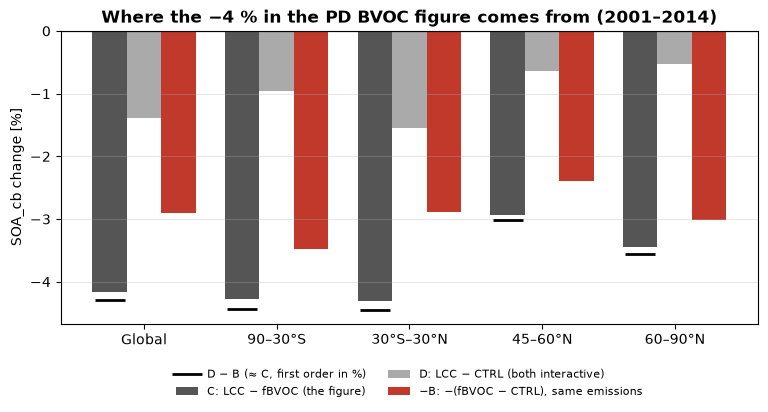

In [6]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
fig, ax = plt.subplots(figsize=(9, 3.8))
items = [('C', 'C: LCC − fBVOC (the figure)', '#5D9A92', 1), ('D', 'D: LCC − CTRL (both interactive)', '#CCCCCC', 1),
         ('B', '−B: −(fBVOC − CTRL), same emissions', '#BC423E', -1)]
x = np.arange(len(BAR_BANDS)); w = 0.26
for i, (k, lab, col, sign) in enumerate(items):
    ax.bar(x + (i - 1) * w, [sign * CH[('14yr', k, 'SOA_cb', b)].mean() for b in BAR_BANDS], w, color=col, label=lab)
ax.plot(x - w, [CH[('14yr', 'D', 'SOA_cb', b)].mean() - CH[('14yr', 'B', 'SOA_cb', b)].mean() for b in BAR_BANDS],
        'k_', ms=22, mew=2, label='D − B (≈ C, first order in %)')
ax.axhline(0, color='k', lw=0.8); ax.set_xticks(x, BAR_BANDS); ax.set_ylabel('SOA_cb change [%]')
ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('Where the −4 % in the PD BVOC figure comes from (2001–2014)', fontweight='bold')
fig.savefig(OUT / 'figures' / 'evidence_bookkeeping.png', dpi=200, bbox_inches='tight')
for b in ('Global', '45–90°N'):
    c, d, bb = (CH[('14yr', k, 'SOA_cb', b)].mean() for k in ('C', 'D', 'B'))
    print(f'{b:8s}: C = {c:+.2f} %  =  D {d:+.2f} %  −  B {bb:+.2f} %   -> B is {100 * bb / -c:.0f} % of C')

### 3d. Global maps of the SOA burden change [%]
B is positive almost everywhere, also over the Southern Ocean and Antarctica, far from any land-cover change. D (no method difference) is small north of 45°N.

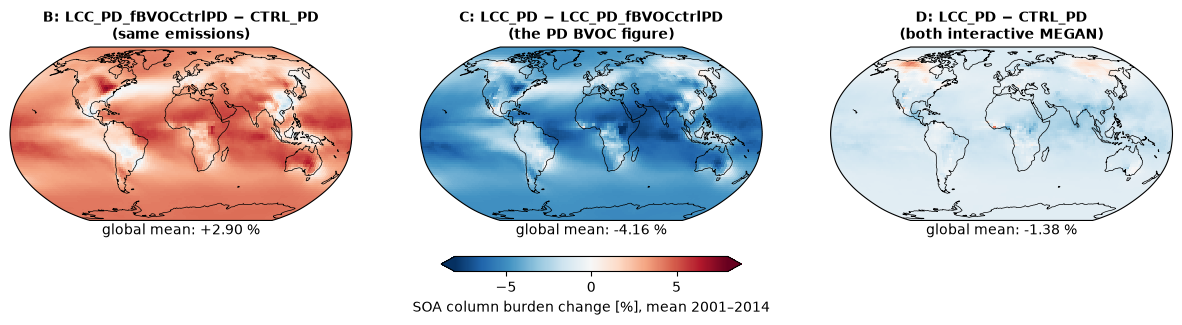

In [7]:
import cartopy.crs as ccrs
soa = {k: F14[k]['SOA_cb'].mean('year') for k in ('ctrl', 'lcc', 'fbvoc')}
maps = [(('fbvoc', 'ctrl'), 'B: LCC_PD_fBVOCctrlPD − CTRL_PD\n(same emissions)'),
        (('lcc', 'fbvoc'), 'C: LCC_PD − LCC_PD_fBVOCctrlPD\n(the PD BVOC figure)'),
        (('lcc', 'ctrl'), 'D: LCC_PD − CTRL_PD\n(both interactive MEGAN)')]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), subplot_kw=dict(projection=ccrs.Robinson()))
for ax, ((k1, k2), title) in zip(axes, maps):
    da = 100 * (soa[k1] / soa[k2] - 1)
    m = da.plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-8, vmax=8, add_colorbar=False)
    ax.coastlines(lw=0.5); ax.set_title(title, fontsize=10, fontweight='bold')
    ax.text(0.5, -0.08, f'global mean: {100 * float(fm.area_weighted_mean(soa[k1]) / fm.area_weighted_mean(soa[k2]) - 1):+.2f} %', transform=ax.transAxes, ha='center')
fig.colorbar(m, ax=axes, orientation='horizontal', fraction=0.05, pad=0.12, shrink=0.5, extend='both',
             label='SOA column burden change [%], mean 2001–2014')
fig.savefig(OUT / 'figures' / 'evidence_global_soa_maps.png', dpi=200, bbox_inches='tight')

### 3e. Summary of the evidence
1. **(a)** Prescribed emissions = CTRL_PD emissions (±0.05 % globally). Globally and in the tropics, the ISOP/MTERP burdens are also unchanged (±0.4 %), yet SOA gas-phase products are +3–4.5 % and the SOA burden +2.9 % (3a). The same parent VOCs give more SOA.
2. **(a)** B > 0 in every latitude band (14/14 years; 30–45°N 13/14) and every season. The chance of 14/14 positive years by noise is 6·10⁻⁵ (3b). The Southern Hemisphere has +3.5 % without any local change in SOA gases (3a, 3d).
3. **(a)** The figure's SOA change is C = D − B: B makes up 70 % of C globally and 84 % at 45–90°N (3c).
4. **(a)** North of 45°N, B is +5.9 % in DJF and +0.5 % in JJA (3b). **(b)** So the boreal part of the artefact is not produced by boreal emissions: it is mostly SOA brought in from lower latitudes outside the growing season.
5. **(a)** North of 30°N the precursor burdens are higher with the same emissions (45–90°N: ISOP +16 %, MTERP +6 %), and surface OH/O₃ do not drop. **(b)** This points to *when* the emissions happen (e.g. more emission at night or in low-OH hours) as a candidate cause, or to a land effect on mixing.
6. **(b)** A land effect cannot easily explain points 1–2: the land cover differs only at 46–82°N. The old-chain spin-up gives LCC more tropical vegetation (+10 % TOTVEGC), which should take up more SOA gases by dry deposition and give **less** SOA in the fBVOC run, not more.
7. **(c)** Candidate causes, none tested yet:
   - a species MEGAN emits that the 19 prescribed files miss;
   - the diurnal timing (30-min stamp, monthly species without a diurnal cycle);
   - the loss of the emission–weather covariance.

   The test run (A) checks the whole method at once.

## 4. Test run (CTRL_PD_fBVOCctrlPD): tables
### 4a. Emission check
A should be ≈ 0 for the emissions. It is not exactly 0: the artefact run receives the 2001–2014 climatology, CTRL_PD the actual 2001–2002 emissions. Compare its size with the SOA change below.

In [8]:
T.loc[['SFISOP', 'SFMTERP', 'SFBCARY', 'cb_ISOP', 'cb_MTERP']].round(2)

band                      Global  90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N  45–90°N
variable period contrast                                                                
SFISOP   2yr    A          -0.08    -0.49       0.07    -5.52     5.83     3.97     5.29
                E           0.00     0.00       0.00     0.00     0.00     0.00     0.00
                B          -0.08    -0.49       0.07    -5.52     5.83     3.97     5.29
                C          -1.98    -0.10      -2.32     5.27    -0.49     1.64    -0.28
                D          -2.06    -0.82      -2.25    -0.90     4.37     4.73     4.39
                C+A        -2.06    -0.59      -2.25    -0.25     5.34     5.61     5.01
         14yr   B          -0.04     0.17      -0.04     0.22     0.32     1.55     0.28
                C          -1.30     0.39      -1.49    -0.16     5.07     1.18     4.69
                D          -1.34     0.37      -1.54    -0.19     5.00     1.23     4.63
                C+Ā        -1.38    -0.09      -1.42    -5.68    10.90     5.14     9.99
SFMTERP  2yr    A           0.09     2.19       0.05    -3.44     3.30     3.25     3.21
                E           0.00     0.00       0.00     0.00     0.00     0.00     0.00
                B           0.09     2.19       0.05    -3.44     3.30     3.25     3.21
                C          -2.20    -3.03      -2.56     3.49    -3.40    12.85    -0.81
                D          -2.12    -1.02      -2.51    -0.26    -0.40    16.41     2.27
                C+A        -2.11    -0.84      -2.50     0.05    -0.09    16.09     2.40
         14yr   B          -0.04     0.21      -0.04     0.05     0.08     0.23     0.07
                C          -1.36     0.37      -1.71     0.27     0.04    13.81     2.23
                D          -1.41     0.35      -1.75     0.23    -0.01    13.77     2.18
                C+Ā        -1.28     2.56      -1.65    -3.17     3.34    17.06     5.44
SFBCARY  2yr    A          -0.05    -2.67       0.01    -4.33     6.65     7.81     6.43
                E           0.00     0.00       0.00     0.00     0.00     0.00     0.00
                B          -0.05    -2.67       0.01    -4.33     6.65     7.81     6.43
                C          -1.98    -0.37      -2.17     3.50    -7.04    10.33    -5.13
                D          -2.04    -3.63      -2.15    -1.34    -1.57    17.89     0.56
                C+A        -2.03    -3.05      -2.15    -0.83    -0.39    18.14     1.30
         14yr   B          -0.04     0.56      -0.04     0.16     0.34     1.24     0.30
                C          -1.29    -1.16      -1.40    -0.80    -1.23    14.62     0.51
                D          -1.34    -1.13      -1.45    -0.84    -1.28    14.57     0.47
                C+Ā        -1.34    -3.84      -1.39    -5.14     5.41    22.43     6.94
cb_ISOP  2yr    A          -0.24    -1.59      -0.28    -2.07    20.46    24.42    19.91
                E          -0.46     0.02      -0.46    -0.46    -0.35    -1.25    -0.49
                B          -0.70    -1.55      -0.74    -2.50    20.12    22.87    19.37
                C          -3.93     1.12      -3.96     0.99    -6.94    -7.94    -7.43
                D          -4.61    -1.07      -4.68    -3.05     9.08    10.31     9.25
                C+A        -4.17    -0.47      -4.24    -1.09    13.53    16.49    12.48
         14yr   B          -0.28    -1.03      -0.35     9.56    16.35    17.05    16.00
                C          -2.46     2.75      -2.46    -8.29    -4.15    -7.09    -4.71
                D          -2.80     1.14      -2.87    -0.41    10.33     5.19     9.52
                C+Ā        -2.71     1.16      -2.74   -10.37    16.32    17.33    15.20
cb_MTERP 2yr    A           0.09     2.51      -0.05    -0.65    10.52     9.06    10.07
                E          -0.39     0.16      -0.39    -0.03    -0.35    -2.43    -0.76
                B          -0.30     2.68      -0.43    -0.67    10.14     6.41     

### 4b. SOA, aerosol number and oxidants [%]

In [9]:
T.loc[['SOA_cb', 'cb_SOA_LV', 'cb_SOA_SV', 'N_AER_sfc', 'OH_sfc', 'O3_sfc', 'NO_sfc']].round(2)

band                       Global  90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N  45–90°N
variable  period contrast                                                                
SOA_cb    2yr    A           3.03     3.55       3.13     1.46     2.84     3.24     2.99
                 E           0.07     0.27       0.06    -0.05     0.02     0.02     0.02
                 B           3.11     3.82       3.18     1.40     2.86     3.26     3.00
                 C          -4.89    -4.77      -5.10    -3.68    -4.14    -4.40    -4.24
                 D          -1.93    -1.13      -2.08    -2.35    -1.41    -1.29    -1.37
                 C+A        -1.85    -1.22      -1.98    -2.23    -1.29    -1.17    -1.25
          14yr   B           2.91     3.48       2.89     2.47     2.39     3.02     2.63
                 C          -4.16    -4.28      -4.31    -3.64    -2.93    -3.44    -3.12
                 D          -1.38    -0.96      -1.55    -1.27    -0.63    -0.53    -0.59
                 C+Ā        -1.13    -0.72      -1.19    -2.19    -0.09    -0.20    -0.14
cb_SOA_LV 2yr    A           3.88     0.16       4.31     2.72    10.93     5.26     8.91
                 E          -0.44    -0.08      -0.50    -0.05     0.23    -0.34     0.03
                 B           3.43     0.07       3.79     2.69    11.18     4.90     8.95
                 C          -6.66    -0.12      -7.64    -2.66    -9.20     5.62    -4.24
                 D          -3.47    -0.05      -4.15    -0.19     0.88    10.73     4.33
                 C+A        -2.78     0.03      -3.32     0.05     1.73    10.88     4.68
          14yr   B           3.98     0.04       4.45     5.53     9.07     3.30     6.97
                 C          -5.85    -0.04      -6.69    -4.78    -7.29     4.99    -3.00
                 D          -2.11     0.00      -2.55     0.43     1.04     8.39     3.70
                 C+Ā        -1.96     0.11      -2.38    -2.06     3.64    10.25     5.92
cb_SOA_SV 2yr    A           2.91     0.35       3.34     3.49     4.23    -0.52     2.29
                 E          -0.30    -0.13      -0.34     0.01     0.46    -0.33     0.15
                 B           2.60     0.22       2.99     3.52     4.71    -0.84     2.44
                 C          -5.01    -0.23      -5.88    -3.34    -3.45     2.95    -0.94
                 D          -2.54    -0.01      -3.07    -0.02     1.07     2.07     1.48
                 C+A        -2.10     0.12      -2.54     0.15     0.78     2.43     1.36
          14yr   B           3.05     0.24       3.52     5.59     3.31    -1.32     1.35
                 C          -4.42    -0.25      -5.16    -4.75    -2.06     2.72    -0.09
                 D          -1.51    -0.02      -1.84     0.53     1.16     1.35     1.24
                 C+Ā        -1.51     0.10      -1.83    -1.26     2.17     2.20     2.20
N_AER_sfc 2yr    A           0.24    -0.11       0.11     0.18     1.18     2.06     1.33
                 E           0.02    -0.07       0.07    -0.07    -0.08     0.08    -0.05
                 B           0.25    -0.17       0.17     0.12     1.10     2.14     1.27
                 C          -0.30     0.20      -0.29    -0.19    -1.18     0.66    -0.87
                 D          -0.05     0.02      -0.12    -0.07    -0.09     2.81     0.39
                 C+A        -0.07     0.09      -0.19    -0.01     0.01     2.72     0.46
          14yr   B           0.27    -0.22       0.20     0.09     1.25     2.10     1.38
                 C          -0.30     0.23      -0.30    -0.16    -1.18     0.42    -0.92
                 D          -0.03     0.01      -0.10    -0.07     0.05     2.52     0.45
                 C+Ā        -0.07     0.13      -0.19     0.02    -0.00     2.48     0.41
OH_sfc    2yr    A          -0.14    -0.40      -0.15     0.14    -0.51    -0.07    -0.39
                 E           0.02    -0.09      -0.02     0.19     0.36    -0.43     0.14
                 B          -0.12    -0.

### 4c. Clouds [%] and net TOA radiation [W m⁻²]

In [10]:
T.loc[['CDNC_incld', 'LWP', 'NET_toa']].round(3)

band                        Global  90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N  45–90°N
variable   period contrast                                                                
CDNC_incld 2yr    A          0.599    0.111      0.593    0.548    1.059    0.982    1.037
                  E          0.020    0.167      0.109    0.058   -0.277   -0.951   -0.480
                  B          0.619    0.278      0.703    0.606    0.779    0.022    0.552
                  C         -0.341   -0.352     -0.163   -0.643   -1.053    0.130   -0.698
                  D          0.276   -0.075      0.540   -0.041   -0.282    0.152   -0.150
                  C+A        0.258   -0.241      0.431   -0.095    0.006    1.112    0.339
           14yr   B          0.296    0.125      0.266    0.400    0.566    0.269    0.476
                  C         -0.391   -0.131     -0.381   -0.522   -0.626    0.019   -0.433
                  D         -0.097   -0.006     -0.116   -0.124   -0.065    0.286    0.040
                  C+Ā        0.207   -0.020      0.213    0.027    0.434    1.001    0.604
LWP        2yr    A          0.011   -0.002      0.033   -0.186    0.109    0.086    0.098
                  E          0.059    0.026      0.105    0.294   -0.108   -0.206   -0.147
                  B          0.071    0.024      0.138    0.107    0.001   -0.120   -0.049
                  C         -0.097   -0.020     -0.216   -0.051   -0.029    0.187    0.058
                  D         -0.026    0.005     -0.078    0.056   -0.029    0.067    0.009
                  C+A       -0.086   -0.022     -0.182   -0.237    0.080    0.274    0.156
           14yr   B         -0.013    0.029      0.029   -0.014   -0.243   -0.166   -0.211
                  C         -0.040   -0.020     -0.115    0.023    0.051    0.156    0.093
                  D         -0.053    0.008     -0.087    0.009   -0.192   -0.011   -0.118
                  C+Ā       -0.029   -0.022     -0.082   -0.164    0.160    0.242    0.191
NET_toa    2yr    A         -0.029   -0.007     -0.048    0.011   -0.018   -0.045   -0.030
                  E          0.054    0.016      0.037    0.054   -0.074    0.493    0.180
                  B          0.025    0.009     -0.011    0.065   -0.092    0.448    0.149
                  C          0.024    0.014      0.026   -0.040    0.127    0.025    0.082
                  D          0.049    0.023      0.015    0.025    0.035    0.474    0.231
                  C+A       -0.005    0.007     -0.022   -0.029    0.109   -0.019    0.051
           14yr   B          0.045   -0.009      0.022    0.034    0.012    0.482    0.223
                  C          0.013    0.003      0.021   -0.000    0.030   -0.008    0.013
                  D          0.058   -0.006      0.044    0.034    0.042    0.475    0.235
                  C+Ā       -0.015   -0.004     -0.026    0.011    0.011   -0.052   -0.017

### 4d. Year by year (SOA_cb, %)
Is A stable from year to year? For reference, fBVOC − CTRL_PD (B) varied by ±0.8 % (global, 1 SD) over 2001–2014.

In [11]:
for band in ('Global', '45–90°N'):
    print(f'--- {band}')
    for (p, k, v, b), x in CH.items():
        if v == 'SOA_cb' and b == band and k in ('A', 'E', 'B', 'C', 'D'):
            yrs = YEARS2 if p == '2yr' else YEARS14
            print(f'{p:5s} {k:2s}', '  '.join(f'{y}: {val:+.2f}' for y, val in zip(yrs, x)) if p == '2yr'
                  else f'mean {x.mean():+.2f}  SD {x.std(ddof=1):.2f}  range {x.min():+.2f} … {x.max():+.2f}')

--- Global
2yr   A  2001: +2.47  2002: +3.60
2yr   E  2001: +0.38  2002: -0.23
2yr   B  2001: +2.86  2002: +3.36
14yr  B  mean +2.91  SD 0.83  range +1.62 … +4.10
2yr   C  2001: -4.38  2002: -5.39
14yr  C  mean -4.16  SD 0.95  range -5.67 … -2.59
2yr   D  2001: -1.65  2002: -2.22
14yr  D  mean -1.38  SD 0.43  range -2.22 … -0.53
--- 45–90°N
2yr   A  2001: +1.62  2002: +4.35
2yr   E  2001: +0.64  2002: -0.59
2yr   B  2001: +2.27  2002: +3.73
14yr  B  mean +2.63  SD 1.15  range +1.07 … +4.80
2yr   C  2001: -3.65  2002: -4.82
14yr  C  mean -3.12  SD 1.60  range -5.15 … -0.59
2yr   D  2001: -1.46  2002: -1.27
14yr  D  mean -0.59  SD 0.91  range -1.84 … +1.12


## 5. Verdict
Thresholds (SOA_cb, global): A > +1.5 % → artefact confirmed; |A| < 0.75 % → the fBVOC excess comes from the land; in between → mixed. They are set from the year-to-year SD of B (0.8 %) and 2 comparison years (SE ≈ 0.6 %).

In [12]:
if ('2yr', 'A', 'SOA_cb', 'Global') not in CH:
    print('Artefact run not processed yet: A, E, C+A pending. Rows B, C, D above are already final.')
else:
    lines = []
    for band in ('Global', '90–30°S', '45–90°N'):
        a, e, c = (CH[('2yr', k, 'SOA_cb', band)].mean() for k in ('A', 'E', 'C'))
        lines.append(f'{band:9s} SOA_cb: A = {a:+.2f} %, E = {e:+.2f} %, C = {c:+.2f} %, C+A = {c + a:+.2f} %'
                     f'  -> the artefact makes up {100 * -a / c:.0f} % of C')
    a = CH[('2yr', 'A', 'SOA_cb', 'Global')].mean()
    verdict = ('ARTEFACT CONFIRMED: prescribing the emissions alone raises SOA' if a > 1.5 else
               'NO ARTEFACT: the fBVOC SOA excess comes from the land (E)' if abs(a) < 0.75 else
               'MIXED: part artefact, part land')
    if STANDIN:
        verdict = 'STAND-IN TEST, NO VERDICT'
    print('\n'.join(lines)); print('\n' + verdict)
    (OUT / 'tables' / 'verdict.txt').write_text('\n'.join(lines + ['', verdict]) + '\n')

Global    SOA_cb: A = +3.03 %, E = +0.07 %, C = -4.89 %, C+A = -1.85 %  -> the artefact makes up 62 % of C
90–30°S   SOA_cb: A = +3.55 %, E = +0.27 %, C = -4.77 %, C+A = -1.22 %  -> the artefact makes up 74 % of C
45–90°N   SOA_cb: A = +2.99 %, E = +0.02 %, C = -4.24 %, C+A = -1.25 %  -> the artefact makes up 71 % of C

ARTEFACT CONFIRMED: prescribing the emissions alone raises SOA


## 6. Figures
### 4a. SOA burden and aerosol number by latitude band

findfont: Failed to find font weight semibold, now using 700.


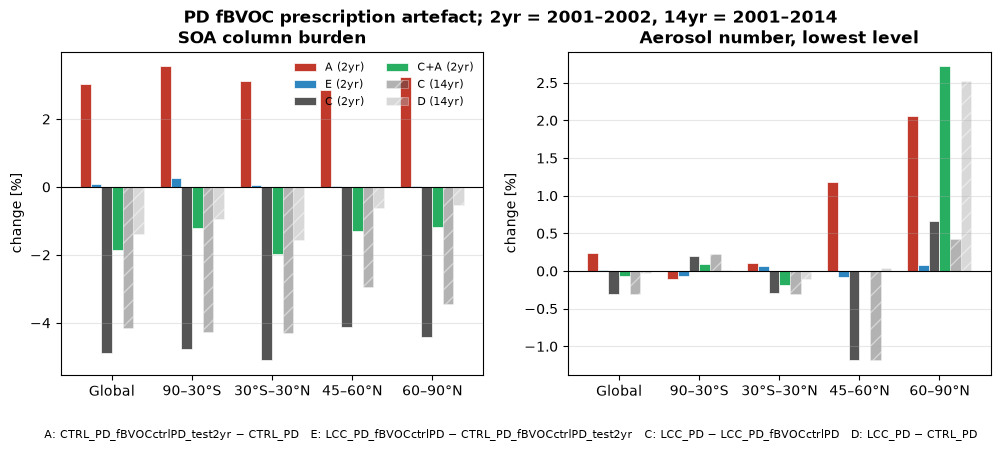

In [13]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
SHOW = [('2yr', 'A'), ('2yr', 'E'), ('2yr', 'C'), ('2yr', 'C+A'), ('14yr', 'C'), ('14yr', 'D')]
COLORS = {'A': '#BC423E', 'E': '#2C3990', 'C': '#5D9A92', 'C+A': '#9A4A84', 'D': '#CCCCCC'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, var, title in zip(axes, ['SOA_cb', 'N_AER_sfc'], ['SOA column burden', 'Aerosol number, lowest level']):
    shown = [(p, k) for p, k in SHOW if (p, k, var, 'Global') in CH]
    w = 0.8 / max(len(shown), 1)
    for i, (p, k) in enumerate(shown):
        vals = [CH[(p, k, var, b)].mean() for b in BAR_BANDS]
        ax.bar(np.arange(len(BAR_BANDS)) + (i - (len(shown) - 1) / 2) * w, vals, w,
               color=COLORS[k], alpha=1.0 if p == '2yr' else 0.45, hatch=None if p == '2yr' else '//',
               label=f'{k} ({p})', edgecolor='white', linewidth=0.5)
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(np.arange(len(BAR_BANDS)), BAR_BANDS)
    ax.set_ylabel('change [%]'); ax.set_title(title, fontweight='semibold')
    ax.grid(axis='y', alpha=0.3)
axes[0].legend(fontsize=8, ncol=2, frameon=False)
fig.suptitle(f'PD fBVOC prescription artefact; 2yr = {YEARS2[0]}–{YEARS2[-1]}, 14yr = 2001–2014'
             + ('  [STAND-IN TEST]' if STANDIN else ''), fontweight='bold')
fig.text(0.5, -0.04, '   '.join(LABELS[k] for k in ('A', 'E', 'C', 'D')), ha='center', fontsize=8)
fig.savefig(OUT / 'figures' / 'artefact_bars_by_band.png', dpi=200, bbox_inches='tight')

### 6b. Zonal mean SOA burden change
An artefact should be flat in latitude; a land or vegetation effect should peak near the changed land (46–82°N) or in the tropics (old-chain spin-up difference).

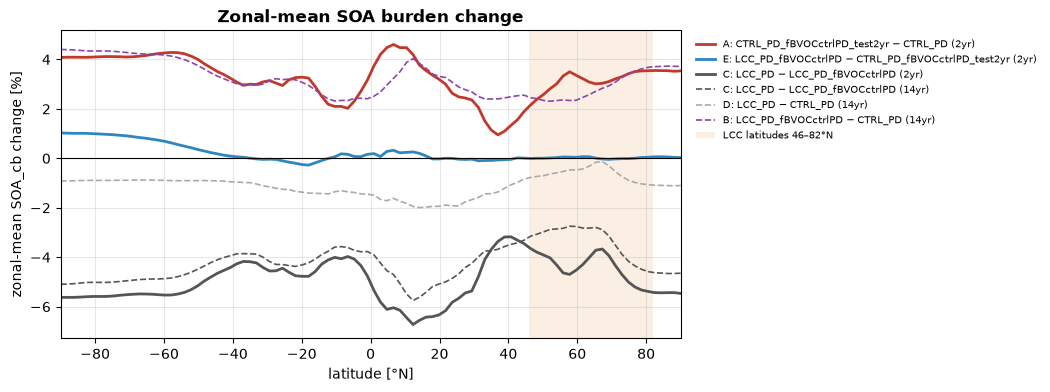

In [14]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
def zonal_pct(F, c1, c2, var='SOA_cb'):
    a = F[c1][var].mean('year').mean('lon'); b = F[c2][var].mean('year').mean('lon')
    return 100 * (a - b) / b

fig, ax = plt.subplots(figsize=(8, 4))
for p, k in [('2yr', 'A'), ('2yr', 'E'), ('2yr', 'C'), ('14yr', 'C'), ('14yr', 'D'), ('14yr', 'B')]:
    F = F2 if p == '2yr' else F14
    c1, c2 = CONTRASTS[k]
    if c1 in F and c2 in F:
        z = zonal_pct(F, c1, c2)
        ax.plot(z['lat'], z, color=COLORS.get(k, '#DE7A3A'), lw=2 if p == '2yr' else 1.2,
                ls='-' if p == '2yr' else '--', label=f'{LABELS[k]} ({p})')
ax.axhline(0, color='k', lw=0.8); ax.axvspan(46, 82, color='#f5cba7', alpha=0.3, lw=0, label='LCC latitudes 46–82°N')
ax.set_xlabel('latitude [°N]'); ax.set_ylabel('zonal-mean SOA_cb change [%]'); ax.set_xlim(-90, 90)
ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1)); ax.grid(alpha=0.3)
ax.set_title('Zonal-mean SOA burden change' + ('  [STAND-IN TEST]' if STANDIN else ''), fontweight='semibold')
fig.savefig(OUT / 'figures' / 'artefact_zonal_soa.png', dpi=200, bbox_inches='tight')

### 6c. Maps north of 45°N: figure contrast, artefact, corrected contrast, land effect
Same style as the context maps. Column C (2001–2014): hatching = not significant (cell-wise t-test + FDR 10 %), mean ± 95 % CI. The 2-yr columns have no hatching (2 years are too few for the test), and the number under them is the mean only. Shared colour scale per row.

findfont: Failed to find font weight semibold, now using 700.


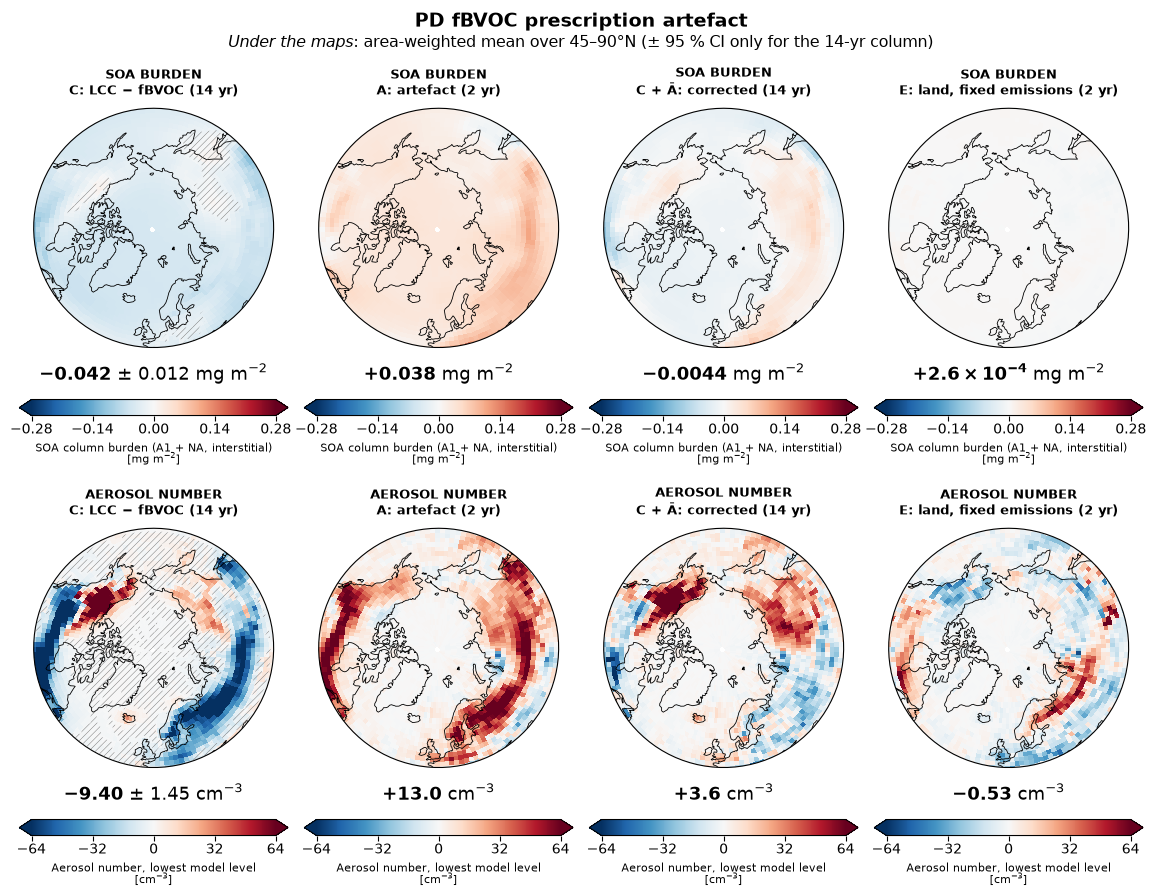

In [15]:
MAP_ROWS = [('SOA_cb', 'SOA BURDEN', 'mg m$^{-2}$', 'SOA column burden (A1 + NA, interstitial)'),
            ('N_AER_sfc', 'AEROSOL NUMBER', 'cm$^{-3}$', 'Aerosol number, lowest model level')]
have_a = 'art' in F2
fig, axes = fm.map_grid(len(MAP_ROWS), 4, titles_every_row=True)
for row, (var, name, units, long) in zip(axes, MAP_ROWS):
    dC = F14['lcc'][var] - F14['fbvoc'][var]
    vmax = fm.symmetric_vmax(dC.mean('year'))
    p = cellwise_pvalue(dC); region = dC['lat'] >= 45
    ns = (~fdr_mask(p, alpha=0.10, within=region)) & np.isfinite(p) & region
    cols = [(f'{name}\nC: LCC − fBVOC (14 yr)', dC.mean('year'), ns, fm._format_interval(*fm.regional_mean_interval(dC, lat_min=45)))]
    if have_a:
        dA = (F2['art'][var] - F2['ctrl'][var]).mean('year')
        dE = (F2['fbvoc'][var] - F2['art'][var]).mean('year')
        cols += [(f'{name}\nA: artefact (2 yr)', dA, None, None),
                 (f'{name}\nC + Ā: corrected (14 yr)', dC.mean('year') + dA, None, None),
                 (f'{name}\nE: land, fixed emissions (2 yr)', dE, None, None)]
    for ax, (title, da, sig, mean_text) in zip(row, cols):
        fm.plot_single_boreal_panel(ax, da, title, units=units, vmax=vmax, extent_lat=45, mean_lat_min=45,
                                    cbar_label=f'{long}\n[{units}]', sig=sig, sig_style='lines', mean_text=mean_text)
    for ax in row[len(cols):]:
        ax.set_axis_off(); ax.set_title('pending: artefact run', fontsize=9)
fm.add_suptitle(fig, 'PD fBVOC prescription artefact' + ('  [STAND-IN TEST]' if STANDIN else ''), 45, y=fm._suptitle_y(fig),
                subtitle=r'$\mathit{Under\ the\ maps}$: area-weighted mean over 45–90°N (± 95 % CI only for the 14-yr column)')
fig.savefig(OUT / 'figures' / 'artefact_maps_45N.png', dpi=200, bbox_inches='tight')

## 7. What next
- **Artefact confirmed** → find its cause: (i) compare every `SF*` species of CTRL_PD_fBVOCctrlPD with CTRL_PD in the raw h0 (a species MEGAN emits but the 19 prescribed files miss); (ii) diurnal timing: CTRL_PD h1 30-min flux vs the flux the fBVOC run receives (30-min stamp offset, monthly species without a diurnal cycle); (iii) SOA budget (`*condTend`, `*DDF`, `*SFWET`): higher production or longer lifetime? Until it is fixed, report BVOC_PD as C+A, or use the LCC − CTRL contrast for SOA.
- **No artefact** → the +3 % comes from the LCC land with fixed emissions (E): look at the SOA dry deposition and the tropical vegetation (old-chain spin-up difference).